In [1]:
# Import libraries for PCA, feature scaling, and visualization.
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [2]:
# Load the wine dataset and preview its first five rows.
df = pd.read_csv("wine.csv")
df.head()

,Alcohol,Malic_Acid,Ash,Ash_Alcanity,Magnesium,Total_Phenols,Flavanoids,Nonflavanoid_Phenols,Proanthocyanins,Color_Intensity,Hue,OD280,Proline,Customer_Segment
0,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065,1
1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050,1
2,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185,1
3,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480,1
4,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735,1


In [3]:
# Inspect dataset columns, data types, and non-null values.
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Alcohol               178 non-null    float64
 1   Malic_Acid            178 non-null    float64
 2   Ash                   178 non-null    float64
 3   Ash_Alcanity          178 non-null    float64
 4   Magnesium             178 non-null    int64  
 5   Total_Phenols         178 non-null    float64
 6   Flavanoids            178 non-null    float64
 7   Nonflavanoid_Phenols  178 non-null    float64
 8   Proanthocyanins       178 non-null    float64
 9   Color_Intensity       178 non-null    float64
 10  Hue                   178 non-null    float64
 11  OD280                 178 non-null    float64
 12  Proline               178 non-null    int64  
 13  Customer_Segment      178 non-null    int64  
dtypes: float64(11), int64(3)
memory usage: 19.6 KB


In [4]:
# Check the dataset dimensions.
df.shape

(178, 14)

In [5]:
# Separate input features from customer-segment labels.
# Remove the target column so only input features remain.
X = df.drop("Customer_Segment",axis=1)
# Keep the correct customer-segment labels separately.
y = df["Customer_Segment"]

In [6]:
# Standardize the input features before PCA.
scaler = StandardScaler()
# fit learns the scaling values; transform applies the standardization.
X_scaled = scaler.fit_transform(X)

In [7]:
# Reduce the dataset to two principal components.
# Keep two principal components so the data can be represented in 2D.
pca = PCA(n_components=2)
# fit learns the scaling values; transform applies the standardization.
X_reduced = pca.fit_transform(X_scaled)

In [10]:
# Compare the original and reduced dataset dimensions.
print("original shape",X.shape)
print("Reduced Shape:", X_reduced.shape)

original shape (178, 13)
Reduced Shape: (178, 2)


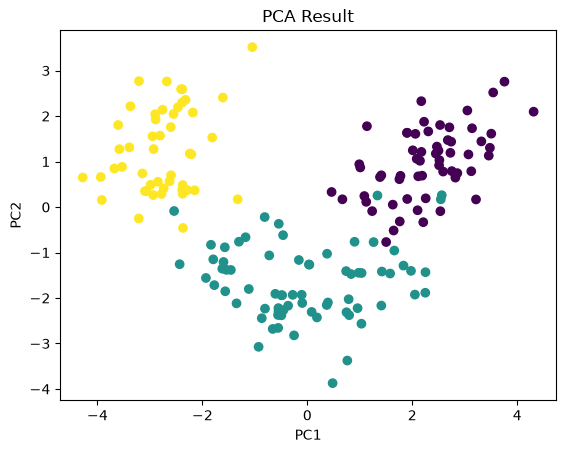

In [11]:
# Visualize the data using the two principal components.
# The colon selects all rows; the number after the comma selects a component column.
plt.scatter(X_reduced[:, 0], X_reduced[:, 1], c=y)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA Result")
plt.show()

In [12]:
# Step 7: Explained variance
# This gives the fraction of total variance explained by each component.
print("Explained Variance:", pca.explained_variance_ratio_)

Explained Variance: [0.36198848 0.1920749 ]
